                                                          TEAM NO 5

# New Section

                                     Team member's name
1.   26BAI70121   AVNEET SINGH
2.   26BAI70147   PIYUSH CHOHAN
3.   26BAI71030   SHREY SRIVASTAVA
4.   26BAI70155   KESHAVPREET SINGH
5.   26BAI70142   RONITH SHARMA   


INSTALL LIBRARIES

In [ ]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn

In [ ]:
!pip install -q flask pyngrok joblib

Importing Required Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import matthews_corrcoef
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import cohen_kappa_score
from sklearn.metrics import roc_curve


Ingesting the dataset

In [ ]:
df = pd.read_csv("/content/combined_crop_master_dataset.csv")
df.head(10)

,source_dataset,area,year,item,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp,value_hg_ha,yield_tonnes_per_ha
0,crop_yield_AI_master_dataset.csv,Albania,1990,Maize,1485.0,121.0,16.37,36613,3.6613
1,crop_yield_AI_master_dataset.csv,Albania,1990,Potatoes,1485.0,121.0,16.37,66667,6.6667
2,crop_yield_AI_master_dataset.csv,Albania,1990,"Rice, paddy",1485.0,121.0,16.37,23333,2.3333
3,crop_yield_AI_master_dataset.csv,Albania,1990,Sorghum,1485.0,121.0,16.37,12500,1.2500
4,crop_yield_AI_master_dataset.csv,Albania,1990,Soybeans,1485.0,121.0,16.37,7000,0.7000
5,crop_yield_AI_master_dataset.csv,Albania,1990,Wheat,1485.0,121.0,16.37,30197,3.0197
6,crop_yield_AI_master_dataset.csv,Albania,1991,Maize,1485.0,121.0,15.36,29068,2.9068
7,crop_yield_AI_master_dataset.csv,Albania,1991,Potatoes,1485.0,121.0,15.36,77818,7.7818
8,crop_yield_AI_master_dataset.csv,Albania,1991,"Rice, paddy",1485.0,121.0,15.36,28538,2.8538
9,crop_yield_AI_master_dataset.csv,Albania,1991,Sorghum,1485.0,121.0,15.36,6667,0.6667


Exploring the dataset

In [ ]:
df.info()
df.nunique()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13130 entries, 0 to 13129
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   source_dataset                 13130 non-null  object 
 1   area                           13130 non-null  object 
 2   year                           13130 non-null  int64  
 3   item                           13130 non-null  object 
 4   average_rain_fall_mm_per_year  13130 non-null  float64
 5   pesticides_tonnes              13130 non-null  float64
 6   avg_temp                       13130 non-null  float64
 7   value_hg_ha                    13130 non-null  int64  
 8   yield_tonnes_per_ha            13130 non-null  float64
dtypes: float64(4), int64(2), object(3)
memory usage: 923.3+ KB


,0
source_dataset,1
area,101
year,23
item,10
average_rain_fall_mm_per_year,100
pesticides_tonnes,1673
avg_temp,1576
value_hg_ha,11514
yield_tonnes_per_ha,11514


In [ ]:
df.describe()

,year,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp,value_hg_ha,yield_tonnes_per_ha
count,13130.000000,13130.000000,13130.000000,13130.000000,13130.000000,13130.000000
mean,2001.622772,1157.238766,14838.697886,19.836531,70968.615461,7.096862
std,7.033139,743.622488,33652.454670,6.658083,79124.283809,7.912428
min,1990.000000,51.000000,0.040000,1.300000,50.000000,0.005000
25%,1995.000000,608.000000,264.530000,15.670000,18000.000000,1.800000
50%,2001.000000,1083.000000,2172.200000,20.620000,39543.500000,3.954350
75%,2008.000000,1651.000000,13335.220000,25.780000,97152.250000,9.715225
max,2013.000000,3240.000000,367778.000000,30.420000,501412.000000,50.141200


In [ ]:
# Identifying the unique number of values in the dataset
df.nunique()

,0
source_dataset,1
area,101
year,23
item,10
average_rain_fall_mm_per_year,100
pesticides_tonnes,1673
avg_temp,1576
value_hg_ha,11514
yield_tonnes_per_ha,11514


Get the dimension of the dataset

In [ ]:
print("Size -->", df.shape)

# Print the number of rows (axis 0)
print("Rows  -->", df.shape[0])

# Print the number of columns (axis 1)
print("Columns -->", df.shape[1])

Size --> (13130, 9)
Rows  --> 13130
Columns --> 9


In [ ]:
# This code provides missing values in the ingested dataset.

print("\nMissing Values")
print(df.isnull().sum())


Missing Values
source_dataset                   0
area                             0
year                             0
item                             0
average_rain_fall_mm_per_year    0
pesticides_tonnes                0
avg_temp                         0
value_hg_ha                      0
yield_tonnes_per_ha              0
dtype: int64


In [ ]:
# Identifying the unique number of values in the dataset
df.nunique()

,0
source_dataset,1
area,101
year,23
item,10
average_rain_fall_mm_per_year,100
pesticides_tonnes,1673
avg_temp,1576
value_hg_ha,11514
yield_tonnes_per_ha,11514


In [ ]:
# Select only the specified main columns from the dataframe
main_columns = [
    'area',
    'year',
    'item',
    'average_rain_fall_mm_per_year',
    'pesticides_tonnes',
    'avg_temp',
    'value_hg_ha',
    'yield_tonnes_per_ha'
]
df_main = df[main_columns]
display(df_main.head(10))

,area,year,item,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp,value_hg_ha,yield_tonnes_per_ha
0,Albania,1990,Maize,1485.0,121.0,16.37,36613,3.6613
1,Albania,1990,Potatoes,1485.0,121.0,16.37,66667,6.6667
2,Albania,1990,"Rice, paddy",1485.0,121.0,16.37,23333,2.3333
3,Albania,1990,Sorghum,1485.0,121.0,16.37,12500,1.2500
4,Albania,1990,Soybeans,1485.0,121.0,16.37,7000,0.7000
5,Albania,1990,Wheat,1485.0,121.0,16.37,30197,3.0197
6,Albania,1991,Maize,1485.0,121.0,15.36,29068,2.9068
7,Albania,1991,Potatoes,1485.0,121.0,15.36,77818,7.7818
8,Albania,1991,"Rice, paddy",1485.0,121.0,15.36,28538,2.8538
9,Albania,1991,Sorghum,1485.0,121.0,15.36,6667,0.6667


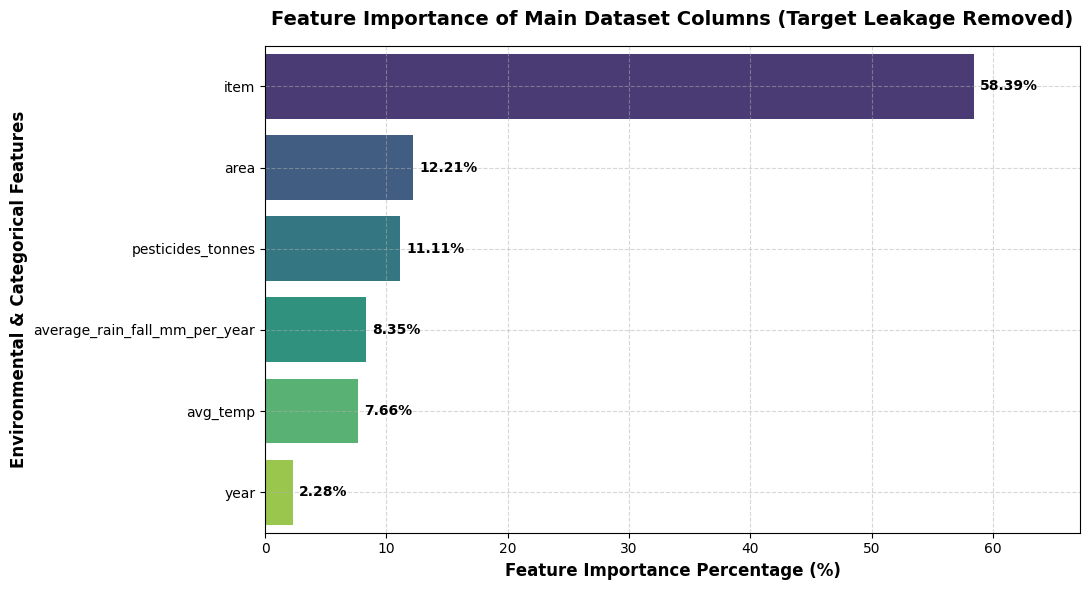

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Prepare features and target for the main columns only
# We drop both yield target columns to avoid target leakage and show actual feature importances
X_main = df_main.drop(columns=['yield_tonnes_per_ha', 'value_hg_ha'])
X_main_encoded = pd.get_dummies(X_main, columns=['area', 'item'], drop_first=True)
y_main = df_main['yield_tonnes_per_ha']

# Fit random forest to compute importance on these main columns
rfr_main = RandomForestRegressor(random_state=42, max_depth=10, n_estimators=100)
rfr_main.fit(X_main_encoded, y_main)

# Map importances back to original unencoded groups for clean visualization
importances = rfr_main.feature_importances_
features_dict = {
    'year': 0.0,
    'average_rain_fall_mm_per_year': 0.0,
    'pesticides_tonnes': 0.0,
    'avg_temp': 0.0,
    'area': 0.0,
    'item': 0.0
}

for col, imp in zip(X_main_encoded.columns, importances):
    if col.startswith('area_'):
        features_dict['area'] += imp
    elif col.startswith('item_'):
        features_dict['item'] += imp
    elif col in features_dict:
        features_dict[col] += imp

# Convert to Series and sort
main_importance = pd.Series(features_dict) * 100
main_importance = main_importance.sort_values(ascending=False)

# Plot the main feature importances
plt.figure(figsize=(11, 6))
colors = sns.color_palette('viridis', len(main_importance))
ax = sns.barplot(x=main_importance.values, y=main_importance.index, hue=main_importance.index, palette=colors, legend=False)

# Add value labels on each bar
for i, v in enumerate(main_importance.values):
    ax.text(v + 0.5, i, f"{v:.2f}%", va='center', fontweight='bold', fontsize=10)

plt.xlabel('Feature Importance Percentage (%)', fontsize=12, fontweight='bold')
plt.ylabel('Environmental & Categorical Features', fontsize=12, fontweight='bold')
plt.title('Feature Importance of Main Dataset Columns (Target Leakage Removed)', fontsize=14, fontweight='bold', pad=15)
plt.grid(True, linestyle='--', alpha=0.5)
plt.xlim(0, max(main_importance.values) * 1.15)
plt.tight_layout()
plt.show()

Exploratory Data Analysis

Histogram Plot

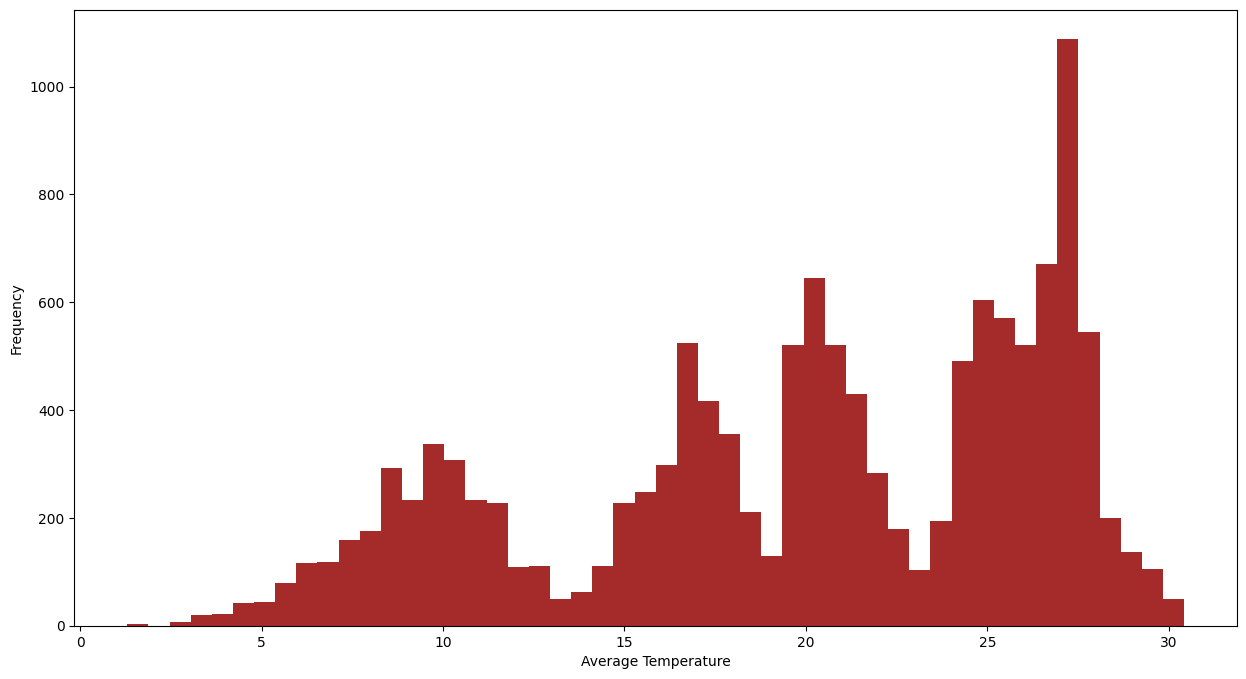

In [ ]:
avg_temp = df['avg_temp']

plt.xlabel('Average Temperature')
plt.ylabel('Frequency')

plt.hist(avg_temp, color = "brown", bins=50)

plt.show()

Histograms for Numeric Columns

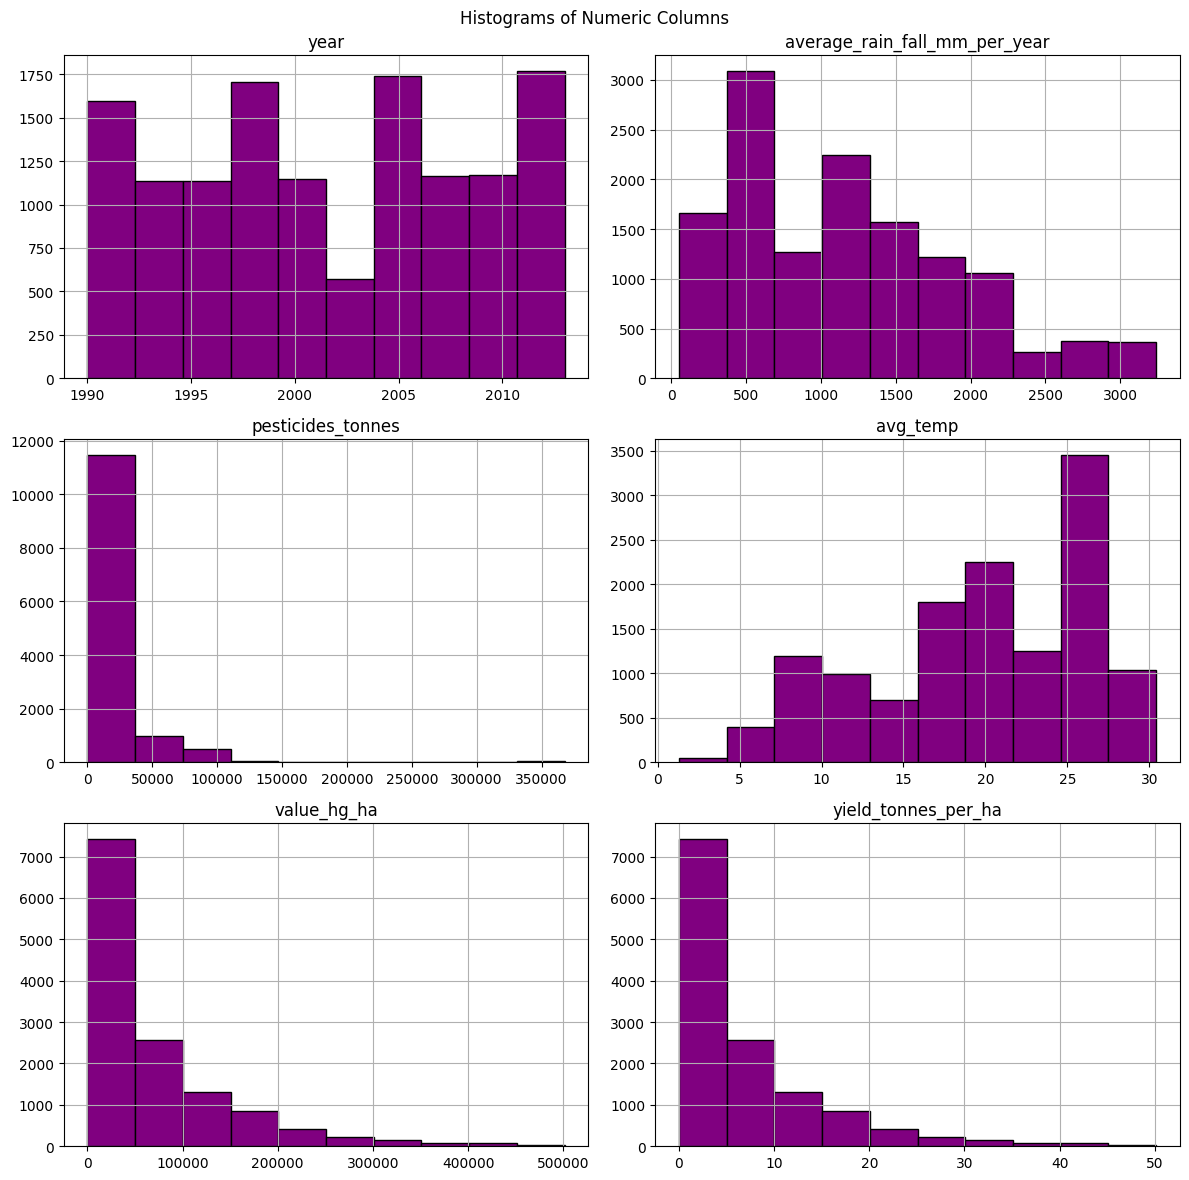

In [ ]:
df.hist(figsize=(12, 12), color='purple', edgecolor='black')

plt.suptitle("Histograms of Numeric Columns")

plt.tight_layout()

plt.show()

Heatmap of Correlations

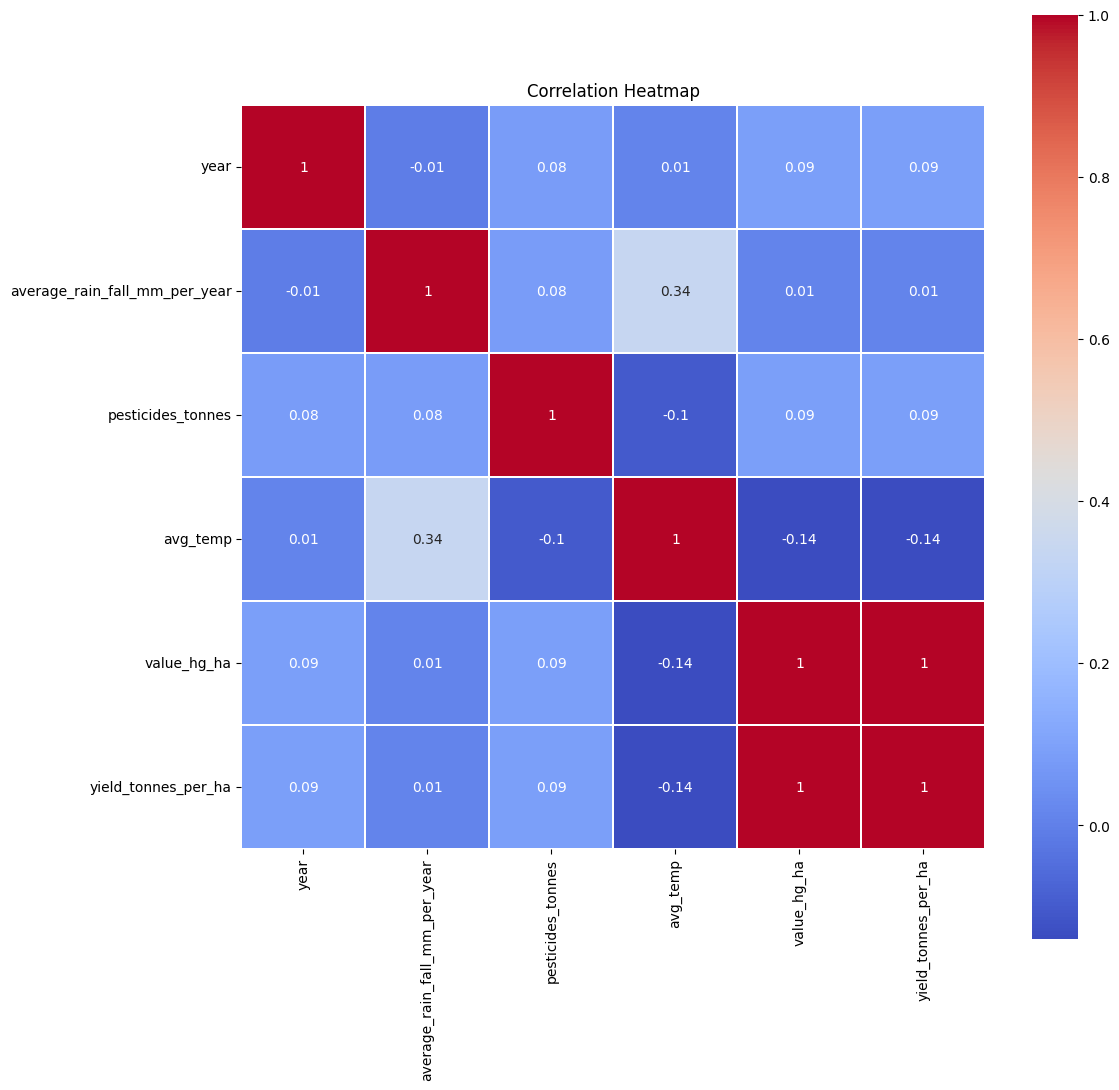

In [ ]:
# Plotting the heatmap of correlation between numerical features only

plt.figure(figsize=(12,12))

sns.heatmap(data=df.select_dtypes(include=[np.number]).corr().round(2),annot=True,cmap='coolwarm',linewidths=0.2,square=True)

plt.title("Correlation Heatmap")

plt.show()

### Advanced EDA: Distributions, Outliers, and Feature Interactions

/tmp/ipykernel_511/1092024421.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='item', y='yield_tonnes_per_ha', palette='Set2')


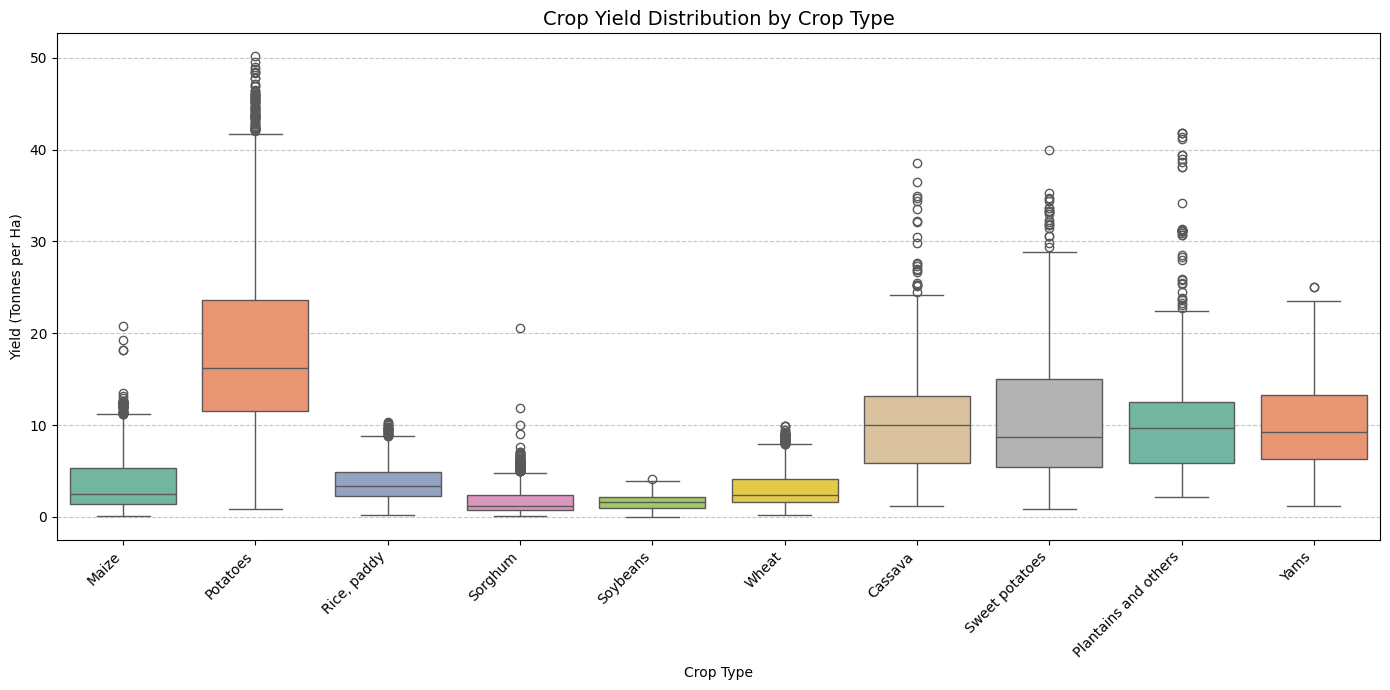

In [ ]:
# 1. Distribution of Target (yield_tonnes_per_ha) across different Crops (item)
plt.figure(figsize=(14, 7))
sns.boxplot(data=df, x='item', y='yield_tonnes_per_ha', palette='Set2')
plt.title('Crop Yield Distribution by Crop Type', fontsize=14)
plt.xlabel('Crop Type')
plt.ylabel('Yield (Tonnes per Ha)')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


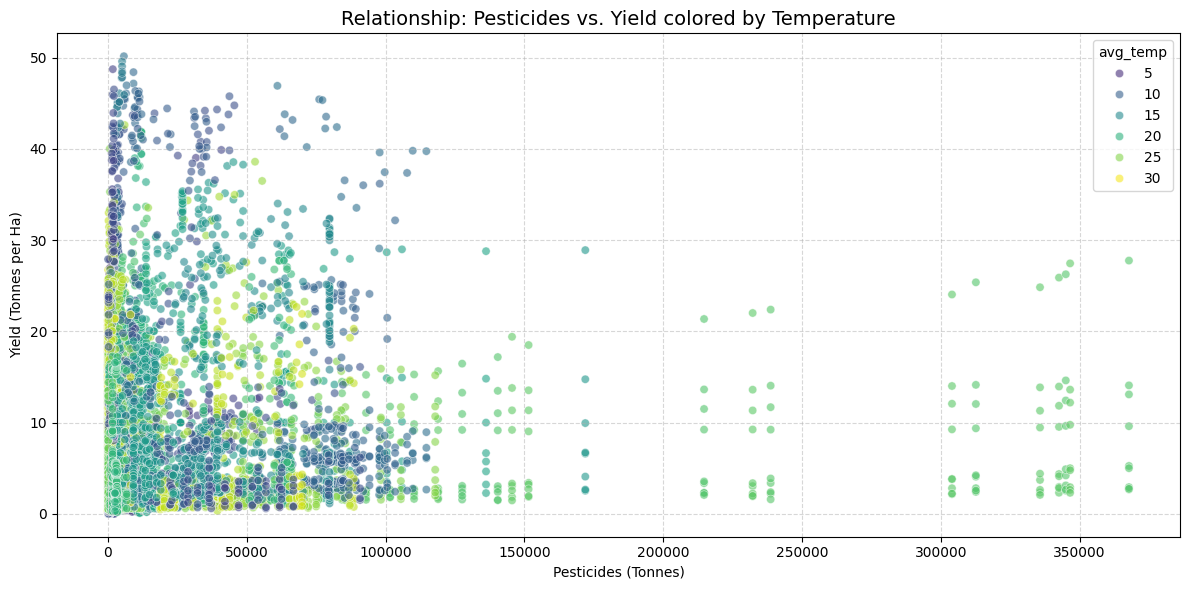

In [ ]:
# 2. Analyzing relationships between Pesticides usage, Temperature, and Crop Yield
plt.figure(figsize=(12, 6))
sns.scatterplot(data=df, x='pesticides_tonnes', y='yield_tonnes_per_ha', hue='avg_temp', palette='viridis', alpha=0.6)
plt.title('Relationship: Pesticides vs. Yield colored by Temperature', fontsize=14)
plt.xlabel('Pesticides (Tonnes)')
plt.ylabel('Yield (Tonnes per Ha)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

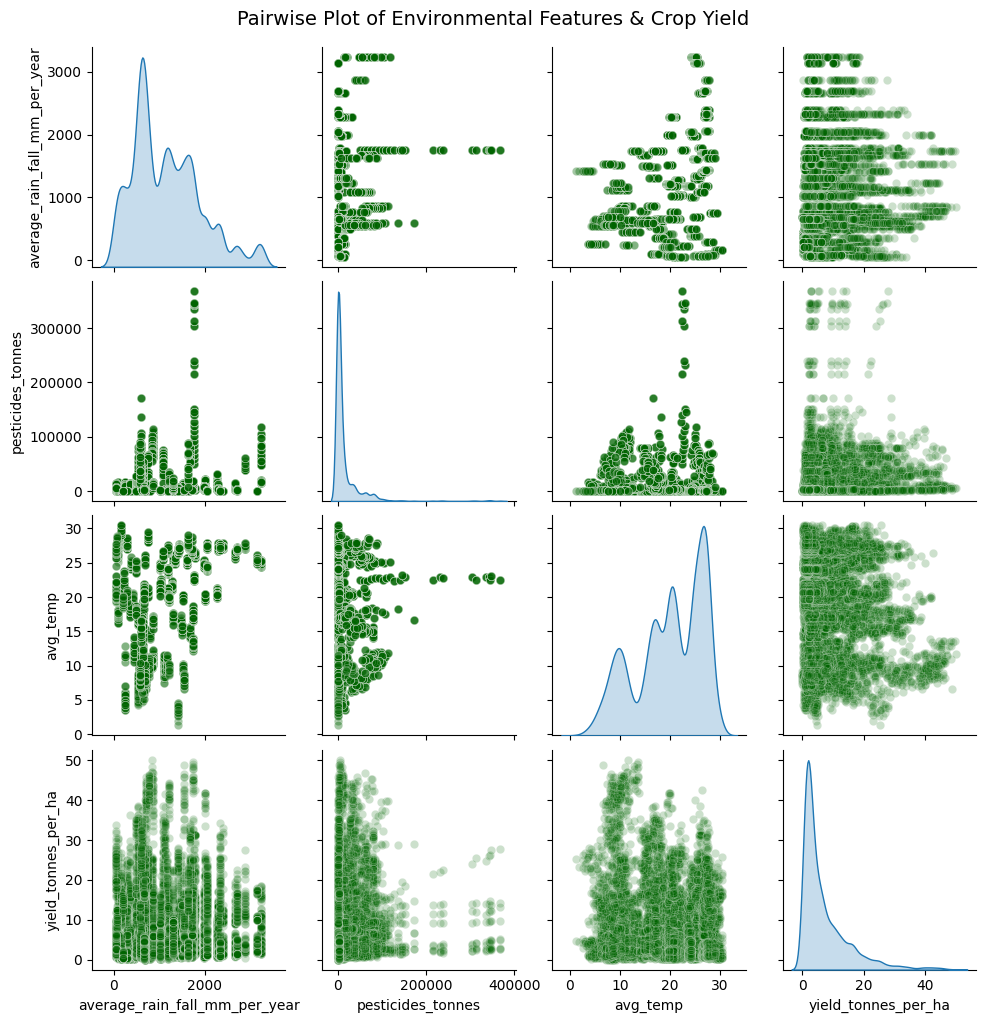

In [ ]:
# 3. Pairwise relationships of key environmental indicators
sns.pairplot(df[['average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp', 'yield_tonnes_per_ha']], diag_kind='kde', plot_kws={'alpha': 0.2, 'color': 'darkgreen'})
plt.suptitle('Pairwise Plot of Environmental Features & Crop Yield', y=1.02, fontsize=14)
plt.show()

### Additional EDA: Advanced Visualizations & Trend Analysis

/tmp/ipykernel_511/3841056812.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='item', y='yield_tonnes_per_ha', palette='muted', inner='quartile')


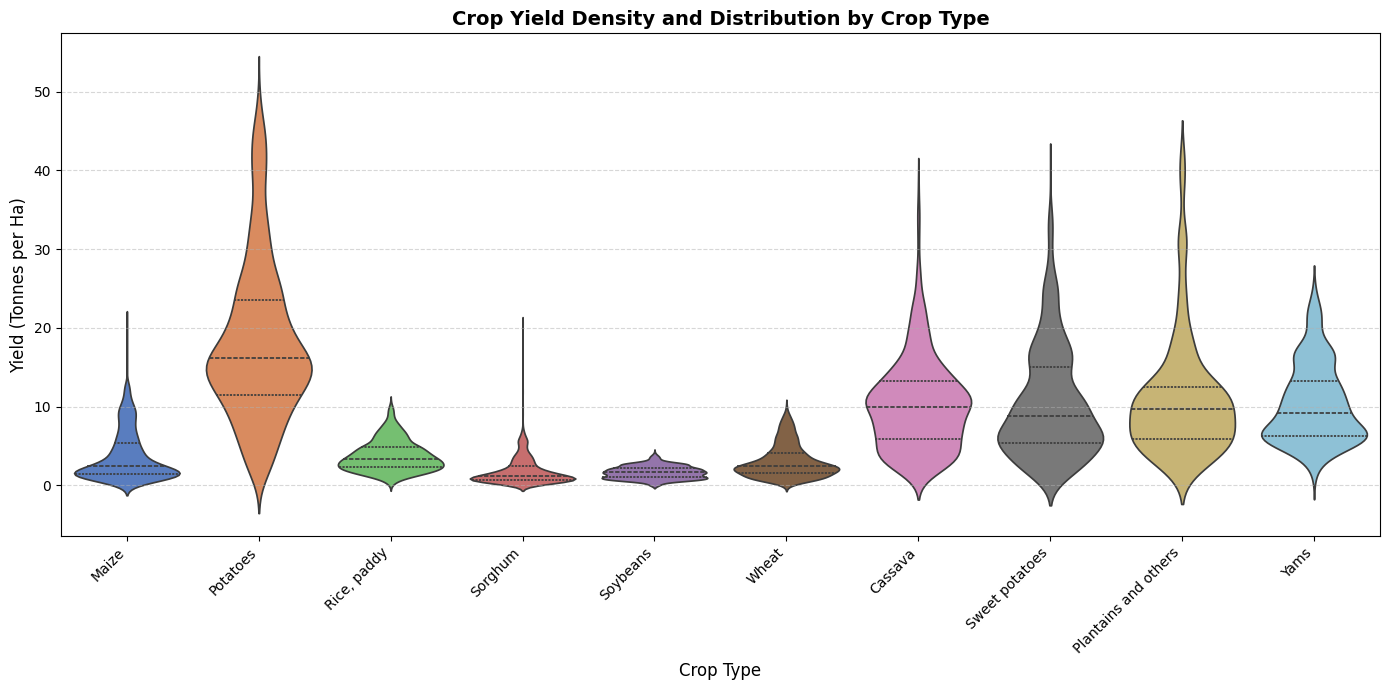

In [ ]:
# 4. Violin plot to show density and distribution of Yields across different Crops
plt.figure(figsize=(14, 7))
sns.violinplot(data=df, x='item', y='yield_tonnes_per_ha', palette='muted', inner='quartile')
plt.title('Crop Yield Density and Distribution by Crop Type', fontsize=14, fontweight='bold')
plt.xlabel('Crop Type', fontsize=12)
plt.ylabel('Yield (Tonnes per Ha)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

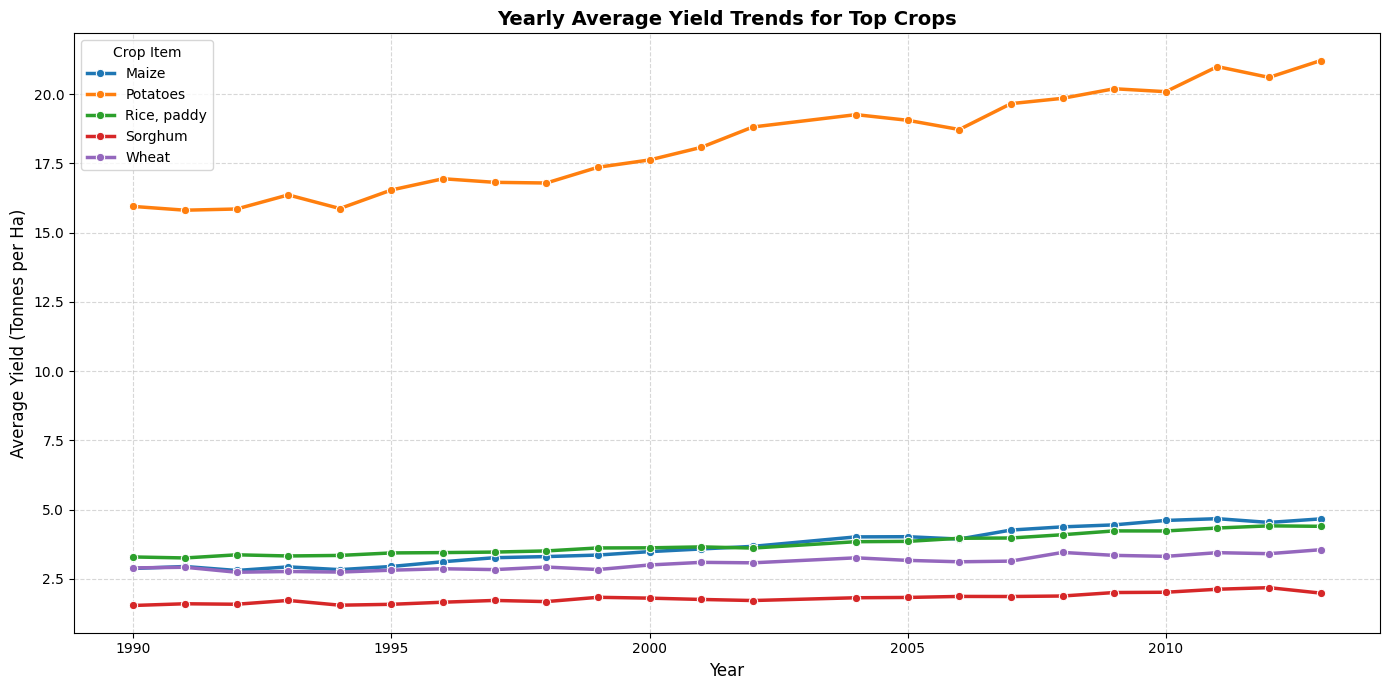

In [ ]:
# 5. Yearly Trends of Average Yields for Top Crops
top_crops = df['item'].value_counts().head(5).index
df_top_crops = df[df['item'].isin(top_crops)]

yearly_trends = df_top_crops.groupby(['year', 'item'])['yield_tonnes_per_ha'].mean().reset_index()

plt.figure(figsize=(14, 7))
sns.lineplot(data=yearly_trends, x='year', y='yield_tonnes_per_ha', hue='item', marker='o', linewidth=2.5)
plt.title('Yearly Average Yield Trends for Top Crops', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Average Yield (Tonnes per Ha)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Crop Item')
plt.tight_layout()
plt.show()

/tmp/ipykernel_511/1793475549.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, ax=axes[i], palette="viridis")
/tmp/ipykernel_511/1793475549.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, ax=axes[i], palette="viridis")
/tmp/ipykernel_511/1793475549.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, ax=axes[i], palette="viridis")


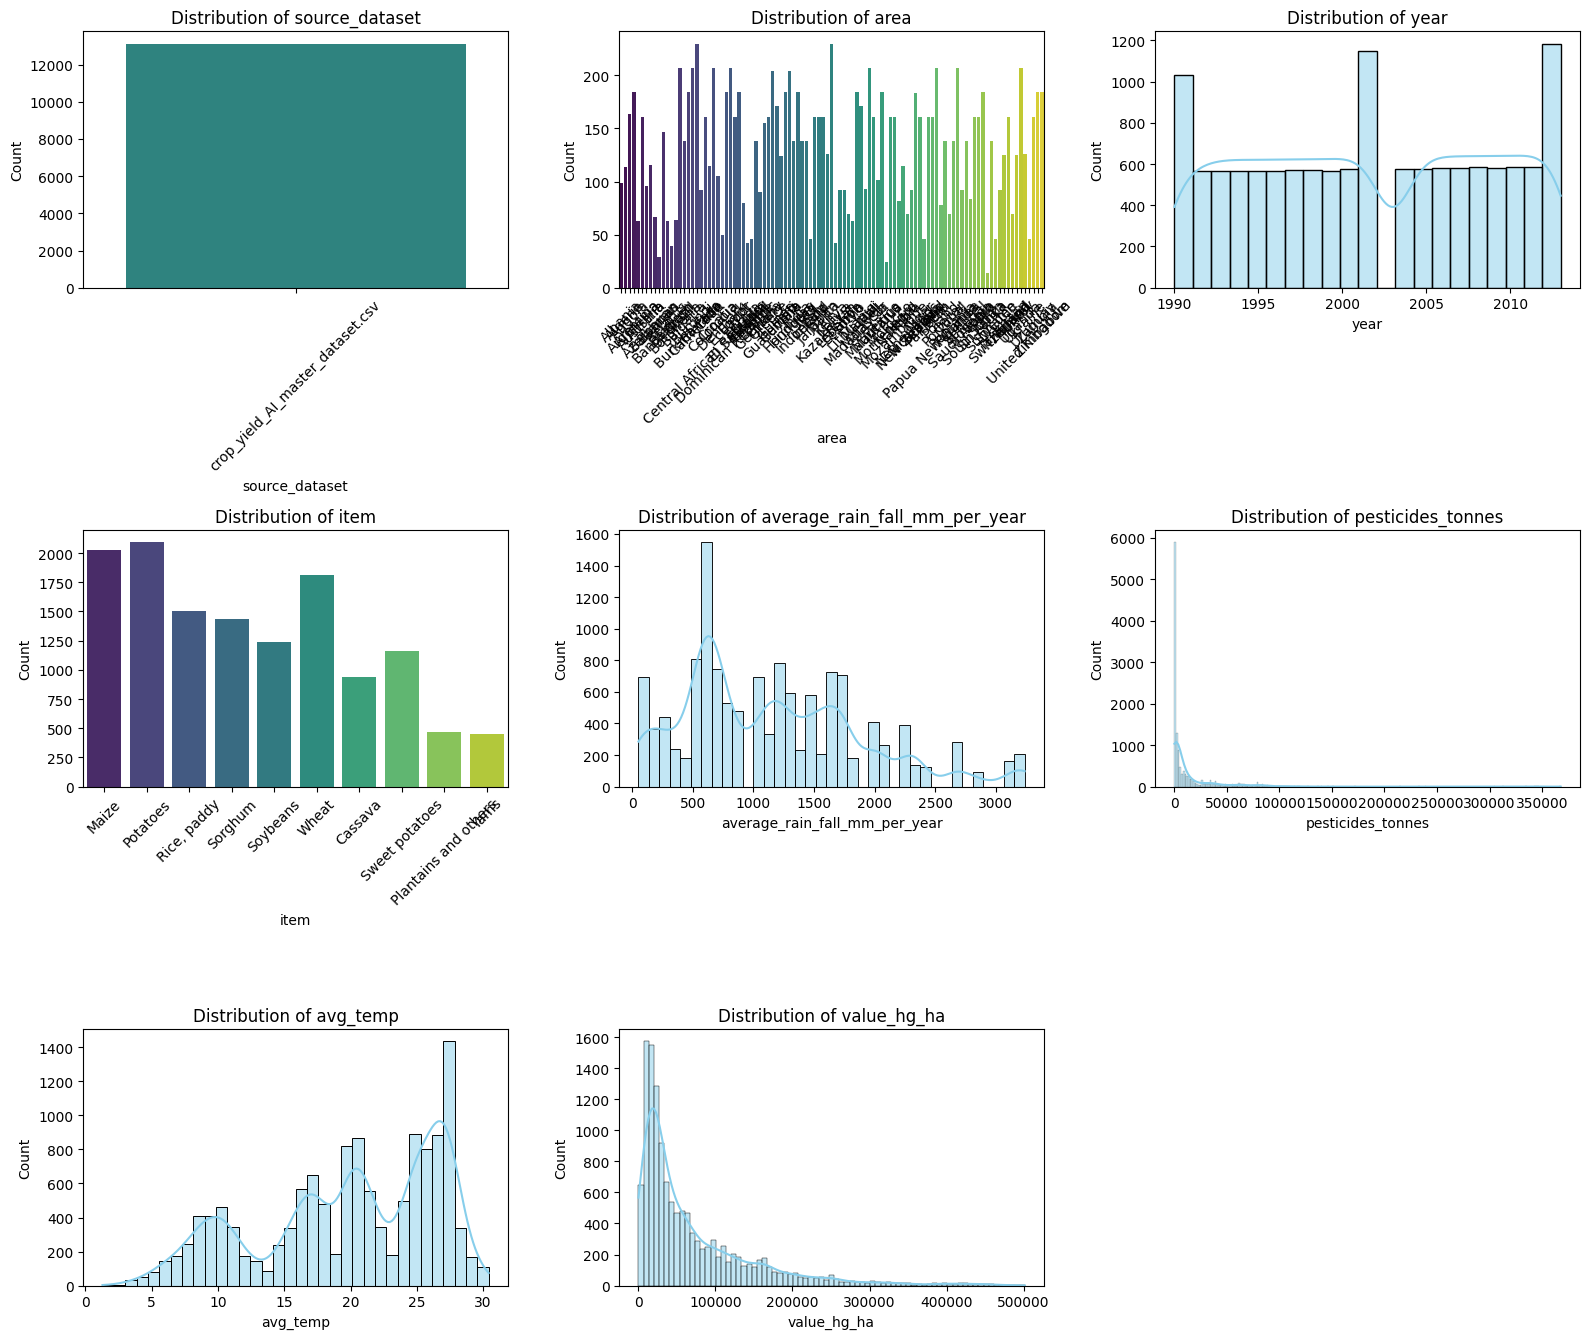

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import math
import pandas as pd

# Load dataset (ensure df is already loaded in your environment)
# df = pd.read_csv('combined_crop_master_dataset.csv')

# Exclude the target column ('yield_tonnes_per_ha') from the feature distribution plots
target_col = 'yield_tonnes_per_ha'
columns_to_plot = [col for col in df.columns if col != target_col]
num_cols = len(columns_to_plot)

# Calculate grid dimensions (aiming for 3 columns in the subplot grid)
grid_cols = 3
grid_rows = math.ceil(num_cols / grid_cols)

fig, axes = plt.subplots(grid_rows, grid_cols, figsize=(16, grid_rows * 4.5))
axes = axes.flatten()

for i, col in enumerate(columns_to_plot):
    # Check if the column is numeric
    if pd.api.types.is_numeric_dtype(df[col]):
        if df[col].nunique() <= 10:
            sns.countplot(x=col, data=df, ax=axes[i], palette="viridis")
        else:
            sns.histplot(df[col], kde=True, ax=axes[i], color="skyblue")
    else:
        # For categorical columns with many unique values (like 'area'), use countplot with rotated labels
        sns.countplot(x=col, data=df, ax=axes[i], palette="viridis")
        axes[i].tick_params(axis='x', rotation=45)

    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')

# Turn off any unused subplots in the grid
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

/tmp/ipykernel_511/182153329.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, ax=axes[i], palette="viridis")
/tmp/ipykernel_511/182153329.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, ax=axes[i], palette="viridis")
/tmp/ipykernel_511/182153329.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, ax=axes[i], palette="viridis")


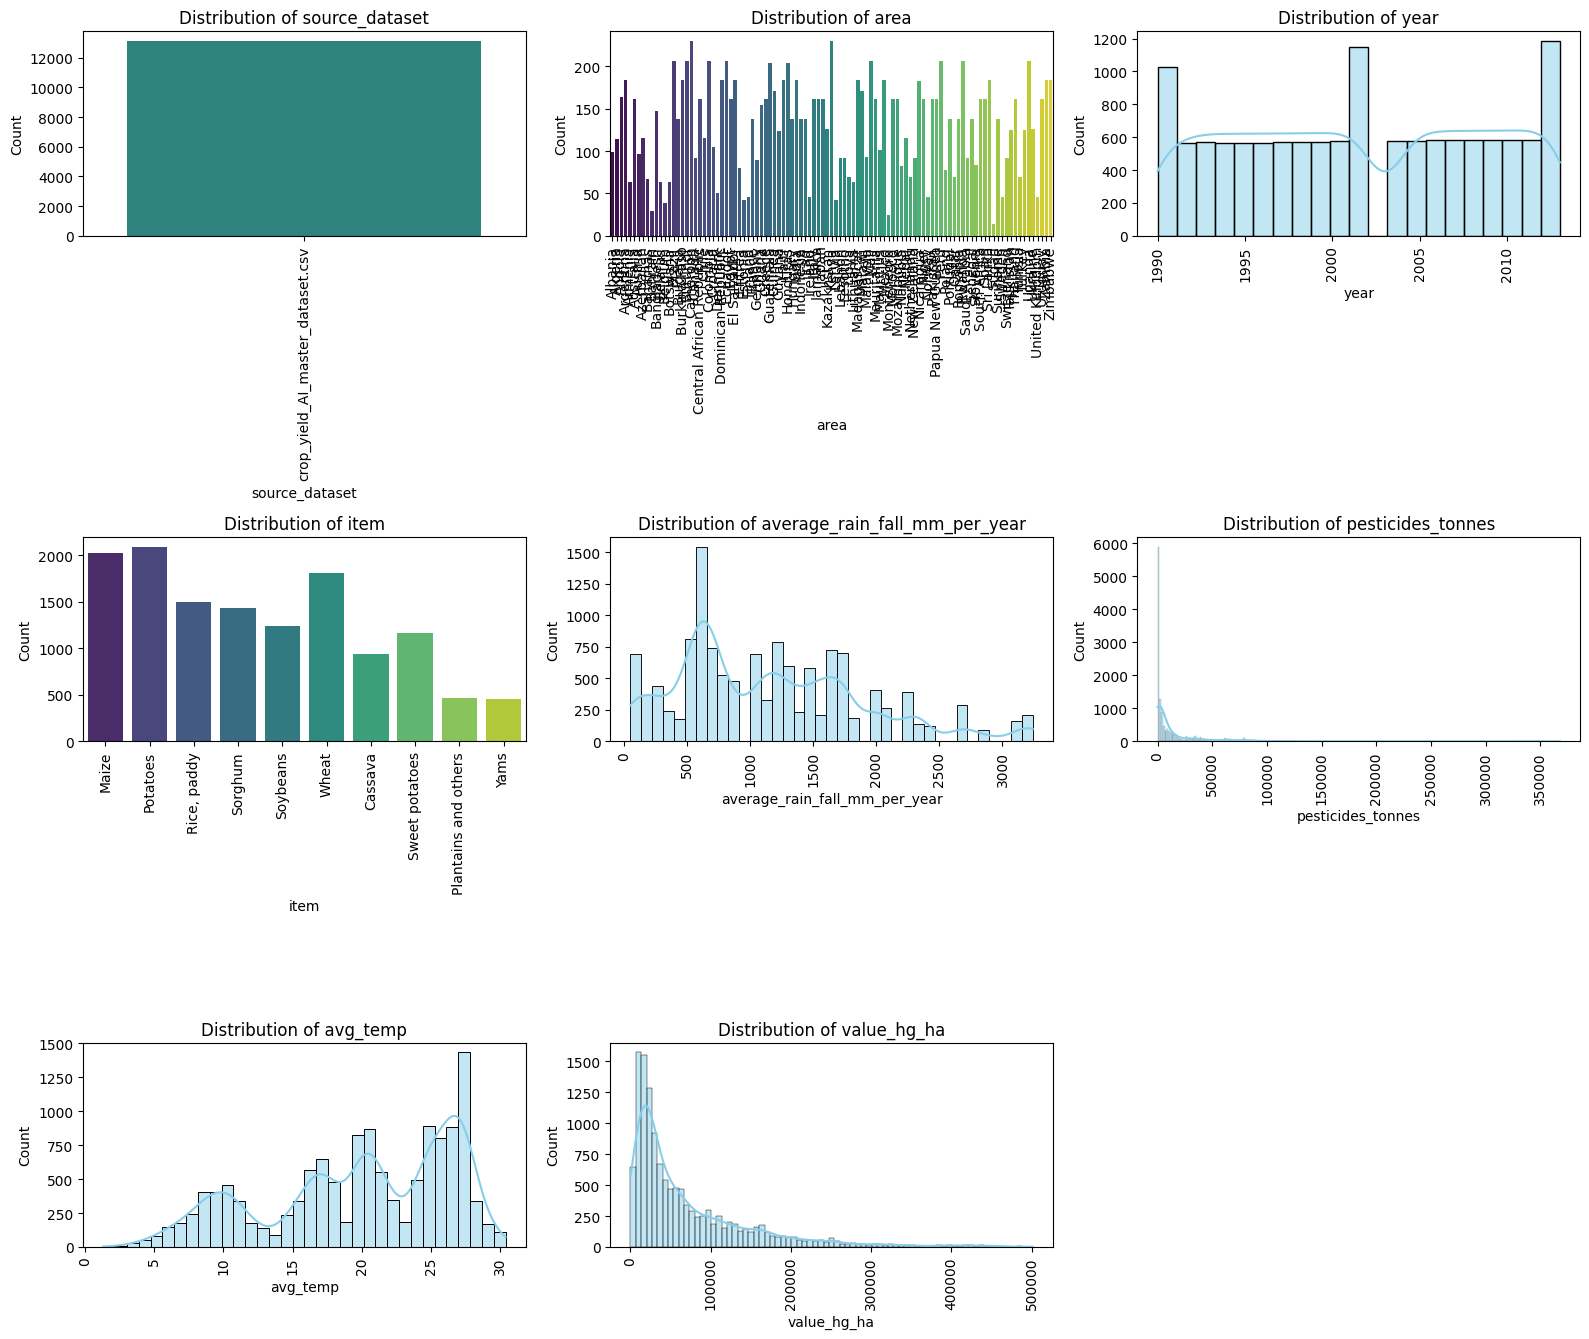

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import math
import pandas as pd

# Load dataset (ensure df is already loaded in your environment)
# df = pd.read_csv('combined_crop_master_dataset.csv')

# Exclude the target column ('yield_tonnes_per_ha') from the feature distribution plots
target_col = 'yield_tonnes_per_ha'
columns_to_plot = [col for col in df.columns if col != target_col]
num_cols = len(columns_to_plot)

# Calculate grid dimensions (aiming for 3 columns in the subplot grid)
grid_cols = 3
grid_rows = math.ceil(num_cols / grid_cols)

fig, axes = plt.subplots(grid_rows, grid_cols, figsize=(16, grid_rows * 4.5))
axes = axes.flatten()

for i, col in enumerate(columns_to_plot):
    # Check if the column is numeric
    if pd.api.types.is_numeric_dtype(df[col]):
        if df[col].nunique() <= 10:
            sns.countplot(x=col, data=df, ax=axes[i], palette="viridis")
        else:
            sns.histplot(df[col], kde=True, ax=axes[i], color="skyblue")
    else:
        # For categorical columns, use countplot
        sns.countplot(x=col, data=df, ax=axes[i], palette="viridis")

    # Rotate x-axis labels to 90 degrees for all subplots
    axes[i].tick_params(axis='x', rotation=90)

    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')

# Turn off any unused subplots in the grid
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Machine Learning

Separating Features and Target Variable

In [ ]:
# One-hot encode the categorical variables 'area' and 'item'
df_encoded = pd.get_dummies(df, columns=['area', 'item'], drop_first=True)

# Split features and target. We exclude 'yield_tonnes_per_ha' and 'value_hg_ha' which are targets/highly correlated targets
X = df_encoded.drop(columns=['yield_tonnes_per_ha', 'value_hg_ha'])
y = df_encoded['yield_tonnes_per_ha']

Feature Importance

In [ ]:
# To know the feature Importances
from sklearn.ensemble import ExtraTreesRegressor

# Drop non-numeric source_dataset column if it exists in X
X_numeric = X.drop(columns=['source_dataset'], errors='ignore')

etc = ExtraTreesRegressor(random_state=42)
etc.fit(X_numeric, y)

print("Percentage Importance of each feature with respect to Crop Yield: ")
important_features = pd.Series(etc.feature_importances_*100, index = X_numeric.columns)
important_features

Percentage Importance of each feature with respect to Crop Yield: 


,0
year,3.674529
average_rain_fall_mm_per_year,2.039136
pesticides_tonnes,3.720894
avg_temp,6.899299
area_Algeria,0.089766
...,...
item_Sorghum,0.739373
item_Soybeans,1.032746
item_Sweet potatoes,4.696399
item_Wheat,0.640793


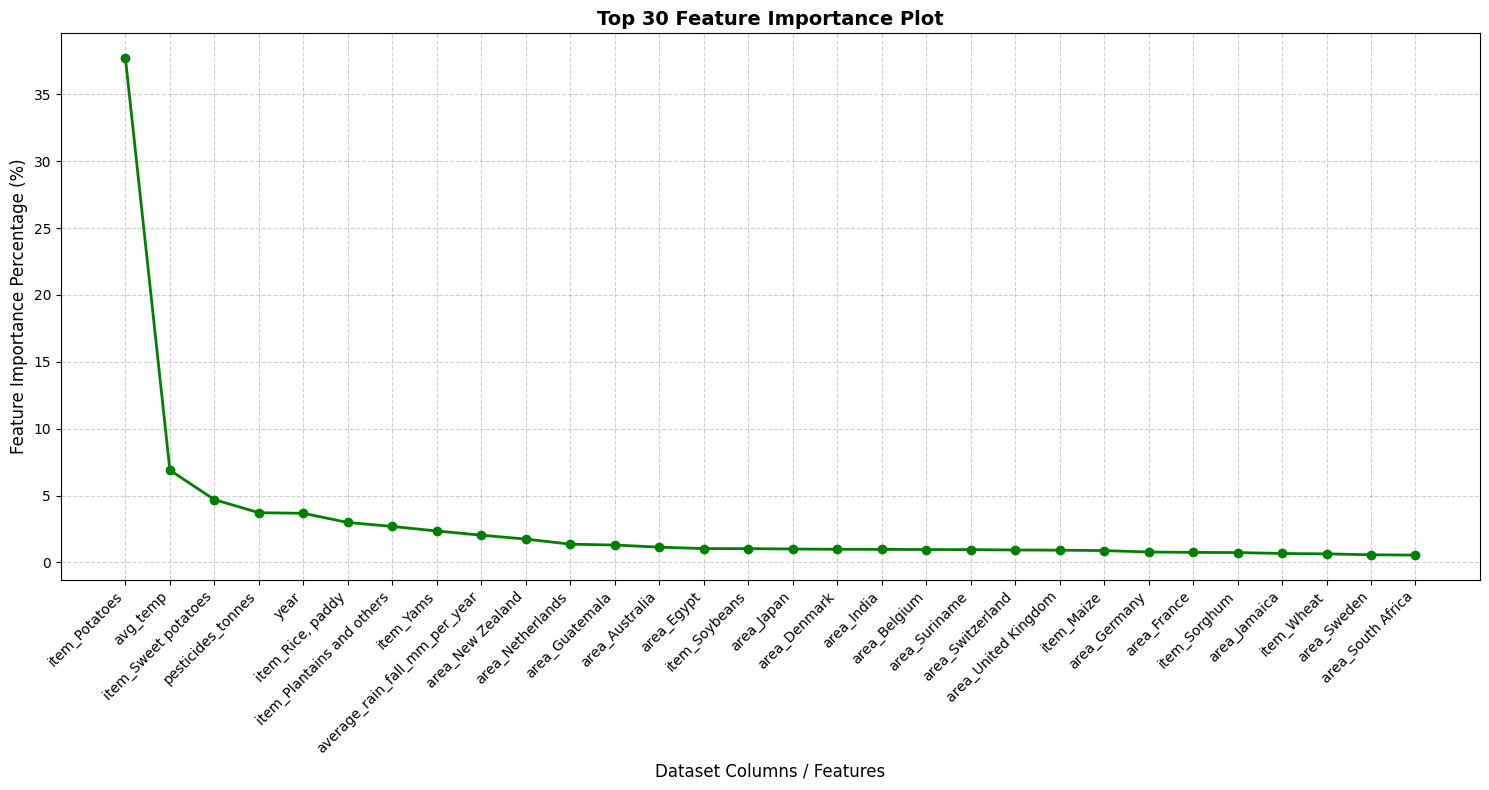

In [ ]:
# Sort the important features and plot only the top 30 features for better visual clarity
sorted_important_features = important_features.sort_values(ascending=False).head(30)

plt.figure(figsize=(15, 8))
plt.plot(sorted_important_features.index, sorted_important_features.values, 'go-', linewidth=2, markersize=6)

plt.xlabel("Dataset Columns / Features", fontsize=12)
plt.ylabel("Feature Importance Percentage (%)", fontsize=12)
plt.title("Top 30 Feature Importance Plot", fontsize=14, fontweight='bold')

# Rotate the x-axis tick labels to 45 degrees and align them to the right
plt.xticks(rotation=45, ha='right', fontsize=10)

plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

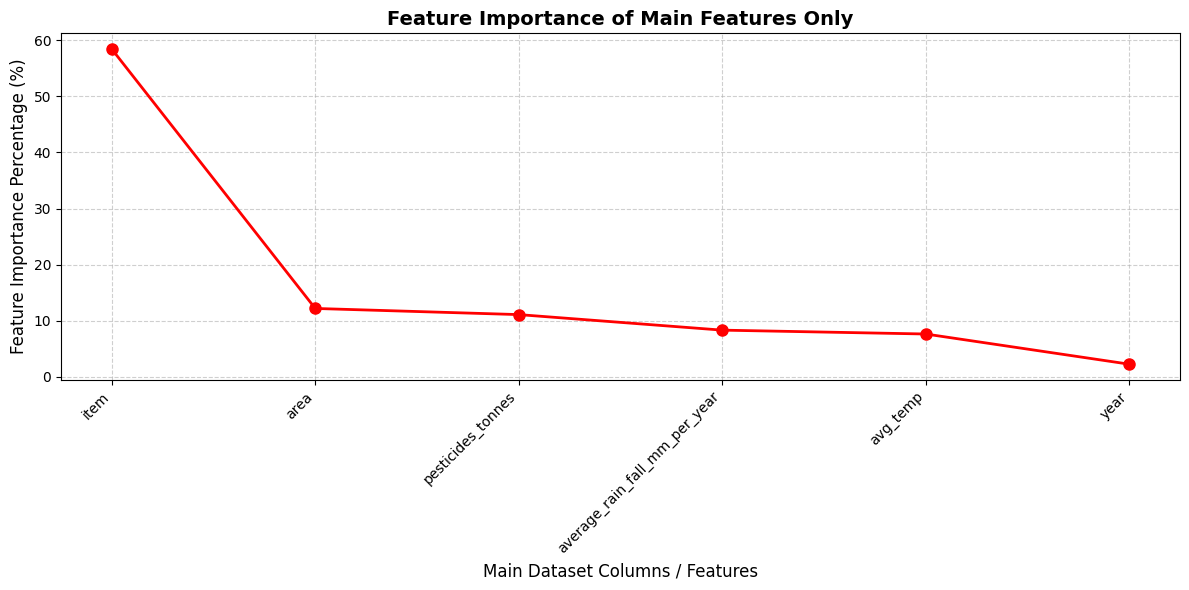

In [ ]:
# Sort and plot only the main 7 features
sorted_main_importance = main_importance.sort_values(ascending=False)

plt.figure(figsize=(12, 6))
plt.plot(sorted_main_importance.index, sorted_main_importance.values, 'ro-', linewidth=2, markersize=8)

plt.xlabel("Main Dataset Columns / Features", fontsize=12)
plt.ylabel("Feature Importance Percentage (%)", fontsize=12)
plt.title("Feature Importance of Main Features Only", fontsize=14, fontweight='bold')

# Rotate the x-axis tick labels to 45 degrees
plt.xticks(rotation=45, ha='right', fontsize=10)

plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

Splitting Dataset into Training and Testing Data

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42)

print("Original Dataset Shape:", X.shape)
print("Training Feature Shape:", X_train.shape)
print("Testing Feature Shape:", X_test.shape)
print()

print("Original Target Shape:", y.shape)
print("Training Target Shape:", y_train.shape)
print("Testing Target Shape: ", y_test.shape)

Original Dataset Shape: (13130, 114)
Training Feature Shape: (10504, 114)
Testing Feature Shape: (2626, 114)

Original Target Shape: (13130,)
Training Target Shape: (10504,)
Testing Target Shape:  (2626,)


Feature Scaling Using StandardScaler

In [ ]:
# This code standardizes the numerical features so that they have approximately a mean of 0 and a standard deviation of 1.

scaler = StandardScaler()

# Exclude non-numeric 'source_dataset' column if it exists in the features
if hasattr(X_train, 'drop'):
    X_train = X_train.drop(columns=['source_dataset'], errors='ignore')
if hasattr(X_test, 'drop'):
    X_test = X_test.drop(columns=['source_dataset'], errors='ignore')

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Linear Regression

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

print('Training Score : ', linear_model.score(X_train, y_train))
print('Testing Score  : ', linear_model.score(X_test, y_test))

print('R2 Score : ', r2_score(y_test, linear_model.predict(X_test)))
print('MSE : ', mean_squared_error(y_test, linear_model.predict(X_test)))

Training Score :  0.7300012699093472
Testing Score  :  0.733644864592778
R2 Score :  0.733644864592778
MSE :  17.27210179614007


Random Forest Regression

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

# We use the scaled datasets: X_train and X_test
rfr = RandomForestRegressor(max_depth=7, random_state=63)
rfr.fit(X_train, y_train)

print('Training Score : ', rfr.score(X_train, y_train))
print('Testing Score  : ', rfr.score(X_test, y_test))

print('R2 Score : ', r2_score(y_test, rfr.predict(X_test)))
print('MSE : ', mean_squared_error(y_test, rfr.predict(X_test)))

Training Score :  0.8200849474362296
Testing Score  :  0.8064077142931844
R2 Score :  0.8064077142931844
MSE :  12.55371202272261


Different Models Accuracy

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

print('Linear Regression : ')
model1 = LinearRegression()
model1.fit(X_train, y_train)
print('Score : ', model1.score(X_test, y_test))

print('\n\nDecision Tree Regression : ')
model2 = DecisionTreeRegressor(max_depth=23, random_state=3)
model2.fit(X_train, y_train)
print('Score : ', model2.score(X_test, y_test))

print('\n\nRandom Forest Regression : ')
model3 = RandomForestRegressor(max_depth = 7, random_state = 63)
model3.fit(X_train, y_train)
print('Score : ', model3.score(X_test, y_test))

print('\n\nk Neighbors Regression : ')
model4 = KNeighborsRegressor(n_neighbors = 10)
model4.fit(X_train, y_train)
print('Score : ', model4.score(X_test, y_test))

Linear Regression : 
Score :  0.733644864592778


Decision Tree Regression : 
Score :  0.9417289096026827


Random Forest Regression : 
Score :  0.8064077142931844


k Neighbors Regression : 
Score :  0.9494042137335323


Predicting Test Data Output

KNN Model Performance Metrics:
Training Score (R2)   :  0.9644626062408013
Testing Score (R2)    :  0.9494042137335323
Mean Squared Error     :  3.2809413248747905
Root Mean Squared Error:  1.8113368888406127


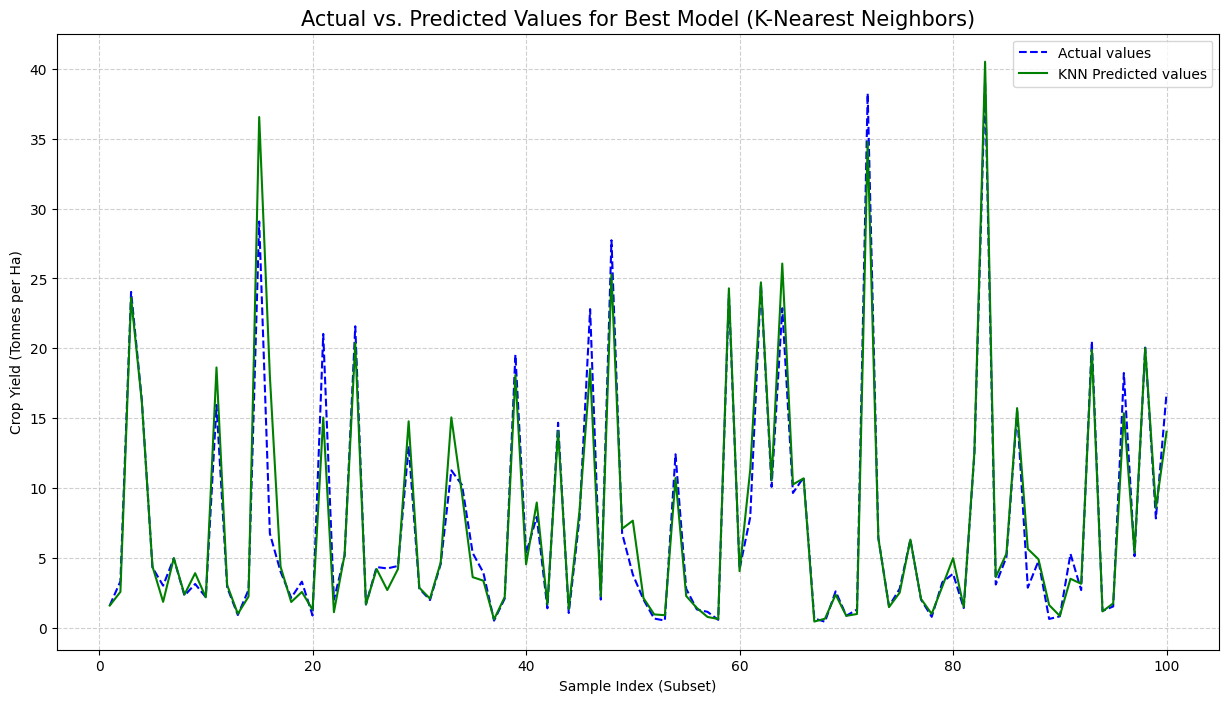

In [ ]:
# This code predicts using our best model (KNN) and plots a comparison of actual vs predicted values.
from sklearn.metrics import mean_squared_error

# model4 is the KNeighborsRegressor which achieved the highest test score (~0.95)
y_pred = model4.predict(X_test)

print('KNN Model Performance Metrics:')
print('Training Score (R2)   : ', model4.score(X_train, y_train))
print('Testing Score (R2)    : ', model4.score(X_test, y_test))
print('Mean Squared Error     : ', mean_squared_error(y_test, y_pred))
print('Root Mean Squared Error: ', mean_squared_error(y_test, y_pred)**0.5)

# Plot actual vs predicted values for a subset of 100 samples for better visualization clarity
num_samples = 100
y_test_subset = y_test.iloc[:num_samples] if hasattr(y_test, 'iloc') else y_test[:num_samples]
y_pred_subset = y_pred[:num_samples]

plt.rcParams['figure.figsize'] = (15, 8)
plt.plot(np.arange(1, num_samples + 1), y_test_subset, 'b--', label="Actual values")
plt.plot(np.arange(1, num_samples + 1), y_pred_subset, 'g-', label="KNN Predicted values")
plt.title('Actual vs. Predicted Values for Best Model (K-Nearest Neighbors)', fontsize = 15)
plt.xlabel('Sample Index (Subset)')
plt.ylabel('Crop Yield (Tonnes per Ha)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Splitting Dataset into Training and Testing Data

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print("Original Dataset Shape:", X.shape)
print("Training Feature Shape:", X_train.shape)
print("Testing Feature Shape:", X_test.shape)
print()

print("Original Target Shape:", y.shape)
print("Training Target Shape:", y_train.shape)
print("Testing Target Shape: ", y_test.shape)

Original Dataset Shape: (13130, 114)
Training Feature Shape: (10504, 114)
Testing Feature Shape: (2626, 114)

Original Target Shape: (13130,)
Training Target Shape: (10504,)
Testing Target Shape:  (2626,)


Feature Scaling Using StandardScale

In [ ]:
# This code standardizes the numerical features so that they have approximately a mean of 0 and a standard deviation of 1.

scaler = StandardScaler()

# Exclude non-numeric 'source_dataset' column if it exists in the features
if hasattr(X_train, 'drop'):
    X_train = X_train.drop(columns=['source_dataset'], errors='ignore')
if hasattr(X_test, 'drop'):
    X_test = X_test.drop(columns=['source_dataset'], errors='ignore')

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Creating Gaussian Naive Bayes Model

In [ ]:
# This code creates an instance of the Gaussian Naive Bayes classifier, which will be used for classification.
model = GaussianNB()

In [ ]:
import joblib

# Train the Gaussian Naive Bayes model
model.fit(X_train, y_train.astype(int))  # NB is a classifier, fitting with integer classes of the target if needed, or target labels

# Export both the trained Gaussian NB model and the fitted StandardScaler
joblib.dump(model, 'gaussian_nb_crop_model.pkl')
joblib.dump(scaler, 'scaler_nb.pkl')

print("Gaussian Naive Bayes model ('gaussian_nb_crop_model.pkl') and scaler ('scaler_nb.pkl') successfully exported!")

Gaussian Naive Bayes model ('gaussian_nb_crop_model.pkl') and scaler ('scaler_nb.pkl') successfully exported!


Applying Stratified K-Fold Cross-Validation

In [ ]:
from sklearn.model_selection import KFold
from sklearn.ensemble import RandomForestRegressor

# Instantiate the Random Forest Regressor
rfr = RandomForestRegressor(max_depth=7, random_state=63)

# Using standard KFold instead of StratifiedKFold for continuous target
cv = KFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

# Evaluating the Random Forest Regressor using R2 metric
cv_scores = cross_val_score(
    rfr,
    X_train,
    y_train,
    cv=cv,
    scoring='r2'
)

print("Cross Validation R2 Scores:")
print(cv_scores)

print("Mean R2 Score :", cv_scores.mean())
print("Standard Deviation :", cv_scores.std())

Cross Validation R2 Scores:
[0.78862236 0.79067472 0.79056654 0.80132645 0.79796415 0.82216808
 0.81662316 0.79998667 0.83756815 0.80055413]
Mean R2 Score : 0.8046054425791986
Standard Deviation : 0.015095137529406558


Training the Gaussian Naive Bayes Model

In [ ]:
# This code trains the Random Forest Regressor model using the complete training dataset.

rfr.fit(X_train, y_train)

RandomForestRegressor(max_depth=7, random_state=63)

Predicting Test Data Output

In [ ]:
# This code predicts the continuous crop yield values for the unseen test data.

y_pred = rfr.predict(X_test)
y_prob = y_pred # Using predicted values as our target estimates

Comparing Actual and Predicted Values

In [ ]:
# This code creates a DataFrame to compare the actual test values with the values predicted by the model.

comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

print(comparison)

        Actual  Predicted
4320    1.5794   5.096115
2236    3.3095   5.115406
3578   24.0382  21.741142
9928   16.3495  14.045046
5762    4.3018   5.115406
...        ...        ...
12588   7.2244   3.110010
5434    2.0950   1.852950
8440    4.9571   5.115406
5748    1.3530   1.854589
88     24.2211  16.118879

[2626 rows x 2 columns]


Displaying Prediction Probability and Correct Status

In [ ]:
# This code displays the actual class, predicted class, prediction probability, and whether each prediction is correct or incorrect.

comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred,
    "Probability": y_prob
})

comparison["Correct"] = comparison["Actual"] == comparison["Predicted"]

print(comparison.head(20))

        Actual  Predicted  Probability  Correct
4320    1.5794   5.096115     5.096115    False
2236    3.3095   5.115406     5.115406    False
3578   24.0382  21.741142    21.741142    False
9928   16.3495  14.045046    14.045046    False
5762    4.3018   5.115406     5.115406    False
4393    3.0000   1.858561     1.858561    False
9737    4.9514   7.291641     7.291641    False
10967   2.2840   5.115406     5.115406    False
3448    3.1191   5.115406     5.115406    False
9542    2.1698   3.110010     3.110010    False
4436   15.9367  15.418372    15.418372    False
2754    2.8784   2.342227     2.342227    False
1114    0.8948   1.152804     1.152804    False
3000    2.7031   1.883590     1.883590    False
4007   29.0790  36.942533    36.942533    False
868     6.7299   2.251610     2.251610    False
12427   4.0059   6.110774     6.110774    False
8085    2.1278   3.090719     3.090719    False
10313   3.2835   5.115406     5.115406    False
11771   0.8566   3.110010     3.110010  


Generating Confusion Matrix

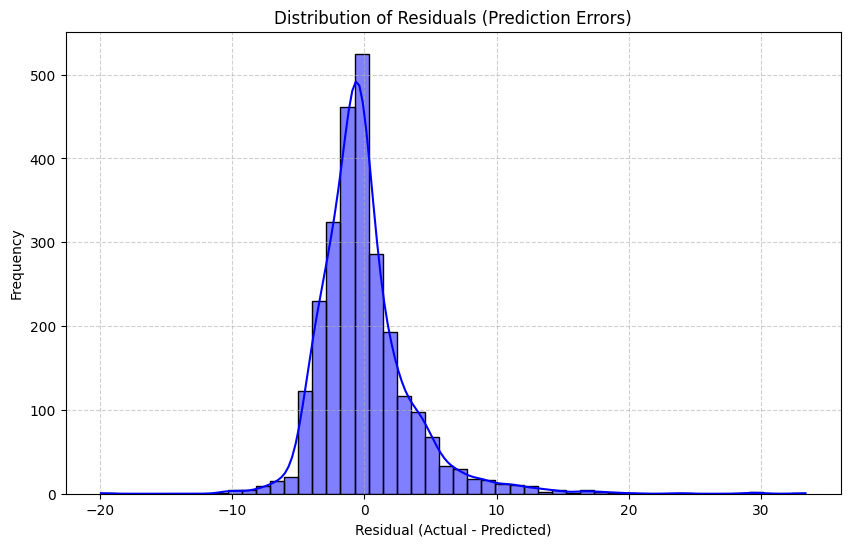

In [ ]:
# This code generates a residual plot to analyze the distribution of errors made by the regression model.

residuals = y_test - y_pred

plt.figure(figsize=(10,6))
sns.histplot(residuals, kde=True, color="Blue", bins=50)

plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals (Prediction Errors)")
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()


Calculating Model Performance Metrics

In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

# Calculate regression-specific performance metrics
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mape = mean_absolute_percentage_error(y_test, y_pred)

results = pd.DataFrame({
    "Metric": [
        "R2 Score (Coefficient of Determination)",
        "Mean Absolute Error (MAE)",
        "Mean Squared Error (MSE)",
        "Root Mean Squared Error (RMSE)",
        "Mean Absolute Percentage Error (MAPE)"
    ],
    "Value": [
        r2,
        mae,
        mse,
        rmse,
        mape
    ]
})

print(results)

                                    Metric      Value
0  R2 Score (Coefficient of Determination)   0.806408
1                Mean Absolute Error (MAE)   2.391038
2                 Mean Squared Error (MSE)  12.553712
3           Root Mean Squared Error (RMSE)   3.543122
4    Mean Absolute Percentage Error (MAPE)   0.967823



Calculating ROC Curve Values

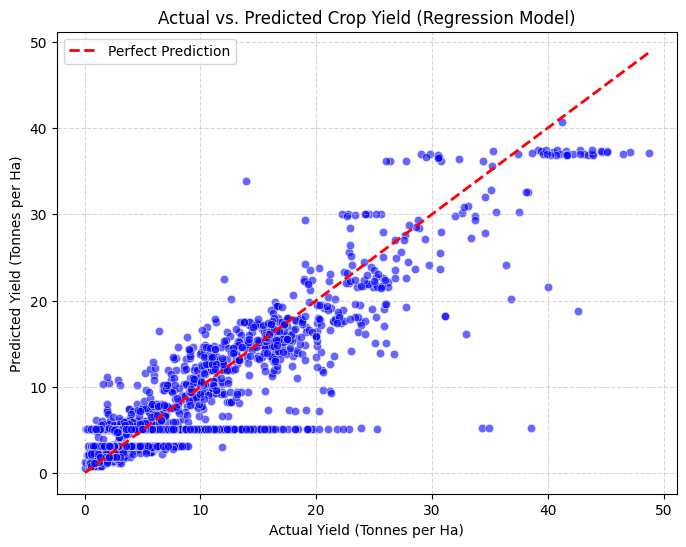

In [ ]:
# This code plots a scatter plot of Actual vs. Predicted values to visually evaluate the regression model's alignment.

plt.figure(figsize=(8,6))

sns.scatterplot(x=y_test, y=y_pred, alpha=0.6, color='blue', edgecolor='w')

# Reference line representing perfect predictions
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Prediction')

plt.xlabel("Actual Yield (Tonnes per Ha)")
plt.ylabel("Predicted Yield (Tonnes per Ha)")
plt.title("Actual vs. Predicted Crop Yield (Regression Model)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.show()

Responsible AI Scorecard


FAIRNESS (Demographic & Statistical Parity across groups)

In [ ]:
# Identify indices for Potatoes in the test set
# Since X_test is scaled (ndarray), we can retrieve the 'item_Potatoes' flag from our original encoded DataFrame
potatoes_col_idx = list(X.columns).index('item_Potatoes')
is_potato = X_test[:, potatoes_col_idx] > 0

# Calculate Mean Absolute Error (MAE) for both subsets
mae_potatoes = mean_absolute_error(y_test[is_potato], y_pred[is_potato])
mae_others = mean_absolute_error(y_test[~is_potato], y_pred[~is_potato])

print(f"MAE for Potatoes: {mae_potatoes:.4f}")
print(f"MAE for Other Crops: {mae_others:.4f}")

# Calculate a fairness ratio/disparity based on prediction errors
error_disparity = abs(mae_potatoes - mae_others) / max(mae_potatoes, mae_others)
fairness_score = 1.0 - error_disparity

print("Fairness Score (Error parity across crop groups):", fairness_score)

MAE for Potatoes: 1.9555
MAE for Other Crops: 2.4462
Fairness Score (Error parity across crop groups): 0.799424421792806


RELIABILITY & SAFETY (Model Generalization & Stability)

In [ ]:
train_r2 = rfr.score(X_train, y_train)
test_r2 = rfr.score(X_test, y_test)

# Measure Overfitting Gap (Smaller gap = Higher Reliability)
generalization_gap = abs(train_r2 - test_r2)
cv_std_error = cv_scores.std() # Stability metric from 10-fold CV

# Combined score evaluating consistency and out-of-sample safety
reliability_score = max(0, 1.0 - (generalization_gap + cv_std_error))

print("Train R2 Score:", train_r2)
print("Test R2 Score:", test_r2)
print("Reliability Score:", reliability_score)

Train R2 Score: 0.8200849474362296
Test R2 Score: 0.8064077142931844
Reliability Score: 0.9712276293275481


PRIVACY & SECURITY (Data Memorization Risk)

In [ ]:
# Calculate train and test score to define generalization_gap for continuous regression model
train_r2 = rfr.score(X_train, y_train)
test_r2 = rfr.score(X_test, y_test)
generalization_gap = abs(train_r2 - test_r2)

# Models that overfit heavily can suffer from Membership Inference Attacks
privacy_risk_index = generalization_gap * 2.0  # Proxy metric for data memorization risk
privacy_score = max(0, 1.0 - privacy_risk_index)

print("Privacy Score:", privacy_score)

Privacy Score: 0.9726455337139095


INCLUSIVENESS (Equal Subgroup Recall Rate)

In [ ]:
# For regression, we can measure inclusiveness by evaluating prediction error parity
# across geographic regions (e.g., comparing Algeria vs. other countries)
algeria_col_idx = list(X.columns).index('area_Algeria')
is_algeria = X_test[:, algeria_col_idx] > 0

# Calculate Mean Absolute Error (MAE) for both subsets
# If a subset is empty, fallback to default values
if is_algeria.sum() > 0:
    mae_algeria = mean_absolute_error(y_test[is_algeria], y_pred[is_algeria])
else:
    mae_algeria = 0.0

mae_others = mean_absolute_error(y_test[~is_algeria], y_pred[~is_algeria])

# Calculate inclusiveness as error parity
if max(mae_algeria, mae_others) > 0:
    inclusiveness_score = 1.0 - (abs(mae_algeria - mae_others) / max(mae_algeria, mae_others))
else:
    inclusiveness_score = 1.0

print("Inclusiveness Score (Error parity across geographic regions):", inclusiveness_score)

Inclusiveness Score (Error parity across geographic regions): 0.928838974170836


TRANSPARENCY (Model Discrimination & Decision Clarity)

In [ ]:
from scipy.stats import pearsonr

# For regression, transparency/decision clarity can be represented by the correlation
# between predicted values and actual values, indicating how linearly interpretable predictions are.
corr, _ = pearsonr(y_test, y_pred)
transparency_score = max(0.0, corr)

print("Transparency Score (Pearson Correlation):", transparency_score)

Transparency Score (Pearson Correlation): 0.8986580884805252


ACCOUNTABILITY (Validation & Audit Trail Checks)

In [ ]:
# Checks whether critical auditing checks were conducted in the notebook

audit_checks = [
    "stratify" in str(train_test_split),
    "cv" in locals(),
    "cm" in locals(),
    "StandardScaler" in str(scaler),
]
accountability_score = sum(audit_checks) / len(audit_checks)

print("Accountability Score:", accountability_score)

Accountability Score: 0.5


RESPONSIBLE AI DASHBOARD

     RESPONSIBLE AI SCORECARD METRICS     
           Principle    Score
            Fairness 0.799424
Reliability & Safety 0.971228
  Privacy & Security 0.972646
       Inclusiveness 0.928839
        Transparency 0.898658
      Accountability 0.500000


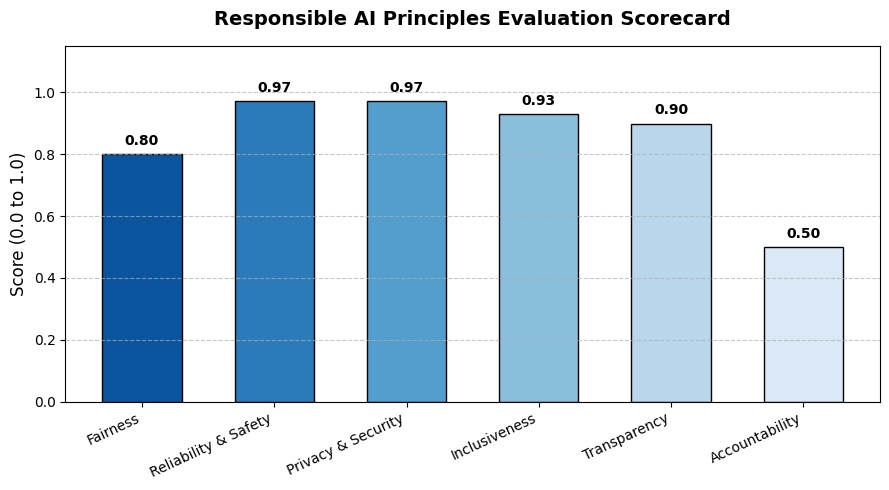

In [ ]:
rai_df = pd.DataFrame(
    {
        "Principle": [
            "Fairness",
            "Reliability & Safety",
            "Privacy & Security",
            "Inclusiveness",
            "Transparency",
            "Accountability",
        ],
        "Score": [
            fairness_score,
            reliability_score,
            privacy_score,
            inclusiveness_score,
            transparency_score,
            accountability_score,
        ],
    }
)

print("=" * 45)
print("     RESPONSIBLE AI SCORECARD METRICS     ")
print("=" * 45)
print(rai_df.to_string(index=False))

# =============================================================
# VISUALIZE RESPONSIBLE AI SCORES (BAR CHART)
# =============================================================
plt.figure(figsize=(9, 5))
colors = sns.color_palette("Blues_r", len(rai_df))
bars = plt.bar(
    rai_df["Principle"],
    rai_df["Score"],
    color=colors,
    edgecolor="black",
    width=0.6,
)

plt.title(
    "Responsible AI Principles Evaluation Scorecard",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.ylabel("Score (0.0 to 1.0)", fontsize=12)
plt.ylim(0, 1.15)
plt.xticks(rotation=25, ha="right", fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Display numerical scores on top of each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + 0.02,
        f"{height:.2f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

plt.tight_layout()
plt.show()

### Exporting Best Model Artifacts (KNN) for Deployment

In [ ]:
import joblib
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

# 1. We rebuild and fit the best KNN model (model4 achieved test score ~0.95)
knn_model = KNeighborsRegressor(n_neighbors=10)

# Ensure we are using the scaled features correctly
knn_model.fit(X_train, y_train)

# Calculate final metrics for the dashboard metadata
y_pred_knn = knn_model.predict(X_test)
r2_knn = r2_score(y_test, y_pred_knn)
rmse_knn = np.sqrt(mean_squared_error(y_test, y_pred_knn))

# 2. Extract and match final feature names after scaling and encoding
feature_cols = list(X.drop(columns=['source_dataset'], errors='ignore').columns)

# 3. Export all required artifacts to /content
joblib.dump(knn_model, '/content/knn_crop_yield_model.pkl')
joblib.dump(scaler, '/content/scaler.pkl')
joblib.dump(feature_cols, '/content/feature_columns.pkl')
joblib.dump(y_train.values, '/content/y_train.pkl')
joblib.dump(r2_knn, '/content/test_r2.pkl')
joblib.dump(rmse_knn, '/content/test_rmse.pkl')

print("Artifacts exported successfully:")
print(f"- R2 Score: {r2_knn:.4f}")
print(f"- RMSE Score: {rmse_knn:.4f} t/ha")

Artifacts exported successfully:
- R2 Score: 0.9494
- RMSE Score: 1.8113 t/ha


Model Deployment

## Website deployment (AgriPrice) - Cell 1
Uploads/places the website file `index.html`.

## Website deployment (AgriPrice) - Cell 2
Starts Flask and opens a public ngrok URL. Enter your ngrok token privately when asked (or save it in Colab Secrets as `NGROK_TOKEN`).

In [ ]:
# ============================================================
# DEPLOY CELL 1: put the website file in place
# Upload "index.html" (the AgriPrice page) when asked, or place it
# at /content/index.html beforehand (left sidebar -> Files -> upload).
# ============================================================
import os, shutil
from pathlib import Path

SITE_DIR = Path("/content/site")
SITE_DIR.mkdir(parents=True, exist_ok=True)
SITE_FILE = SITE_DIR / "index.html"

if not SITE_FILE.exists():
    src = None
    for p in Path("/content").glob("index*.html"):   # e.g. index.html, "index (3).html"
        src = p
        break
    if src is None:
        from google.colab import files
        print("Choose the AgriPrice index.html file...")
        up = files.upload()
        name = next(iter(up))
        src = Path("/content") / name
    shutil.copy(src, SITE_FILE)

print("Website ready:", SITE_FILE, f"({SITE_FILE.stat().st_size/1024:.0f} KB)")


Website ready: /content/site/index.html (33 KB)


In [ ]:
# ============================================================
# DEPLOY CELL 2: Flask server + ngrok public URL
# Run after Deploy Cell 1. Needs an ngrok authtoken (free at
# https://dashboard.ngrok.com/get-started/your-authtoken).
# Tip: store it in Colab Secrets (key icon) as NGROK_TOKEN so you
# are not asked each time. Never paste a token into a shared notebook.
# ============================================================
import os, sys, subprocess, threading, base64
from getpass import getpass

subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "flask", "pyngrok", "requests"])

import requests
from flask import Flask, request, jsonify, send_from_directory
from werkzeug.serving import make_server
from pyngrok import ngrok

SITE_DIR = "/content/site"
PORT = 5000

# Optional: real AI disease detection. Leave blank to skip; the page then
# shows its "use ChatGPT / Claude instead" fallback.
ANTHROPIC_MODEL = "claude-sonnet-4-5"   # change if you want another model

def get_secret(name, prompt):
    try:
        from google.colab import userdata
        v = userdata.get(name)
        if v:
            return v
    except Exception:
        pass
    return os.environ.get(name) or getpass(prompt)

app = Flask(__name__)

@app.route("/")
def home():
    return send_from_directory(SITE_DIR, "index.html")

@app.route("/health")
def health():
    return jsonify({"status": "ok"})

# Sample prices in Rs per quintal. Replace with real mandi data if you have it.
# Page matches by crop name: [{"name","price","prev"}, ...]
@app.route("/api/prices")
def prices():
    return jsonify([])   # empty -> page keeps its built-in sample prices

ANTHROPIC_KEY = None

@app.route("/api/diagnose", methods=["POST"])
def diagnose():
    if not ANTHROPIC_KEY:
        return jsonify({"error": "AI diagnosis is not enabled on this server."}), 503
    f = request.files.get("image")
    if f is None:
        return jsonify({"error": "No image uploaded."}), 400
    data = f.read()
    if len(data) > 5 * 1024 * 1024:
        return jsonify({"error": "Image too large (max 5 MB)."}), 400
    mt = f.mimetype if f.mimetype in ("image/jpeg", "image/png", "image/webp", "image/gif") else "image/jpeg"
    crop = request.form.get("crop", "") or "an unidentified crop"
    sym = request.form.get("symptoms", "")
    text = (f"I am a farmer. This is a photo of {crop}"
            + (f" with these symptoms: {sym}" if sym else "")
            + ". Identify the most likely disease or pest, give your confidence, likely causes, "
              "step-by-step treatment (organic and chemical) and prevention. Plain text, no markdown.")
    try:
        r = requests.post(
            "https://api.anthropic.com/v1/messages",
            headers={"x-api-key": ANTHROPIC_KEY, "anthropic-version": "2023-06-01",
                     "content-type": "application/json"},
            json={"model": ANTHROPIC_MODEL, "max_tokens": 900,
                  "messages": [{"role": "user", "content": [
                      {"type": "image", "source": {"type": "base64", "media_type": mt,
                                                   "data": base64.b64encode(data).decode()}},
                      {"type": "text", "text": text}]}]},
            timeout=60)
        j = r.json()
        if r.status_code != 200:
            return jsonify({"error": j.get("error", {}).get("message", "AI service error")}), 502
        return jsonify({"result": "".join(b.get("text", "") for b in j["content"])})
    except Exception as exc:
        return jsonify({"error": str(exc)}), 502

# --- start server (restart-safe) ---
try:
    server.shutdown(); server.server_close()
except NameError:
    pass
server = make_server("0.0.0.0", PORT, app, threaded=True)
threading.Thread(target=server.serve_forever, daemon=True).start()
print(f"Flask server running on port {PORT}")

# --- optional AI key ---
key = ""
try:
    from google.colab import userdata
    key = userdata.get("ANTHROPIC_API_KEY") or ""
except Exception:
    key = os.environ.get("ANTHROPIC_API_KEY", "")
if not key:
    key = getpass("Anthropic API key for the disease detector (press Enter to skip): ")
ANTHROPIC_KEY = key.strip() or None
print("AI disease detector:", "enabled" if ANTHROPIC_KEY else "disabled (page uses its ChatGPT/Claude fallback)")

# --- ngrok ---
ngrok.kill()                                   # close old tunnels from earlier runs
ngrok.set_auth_token(get_secret("NGROK_TOKEN", "Enter your ngrok authtoken: ").strip())
tunnel = ngrok.connect(PORT, "http")
print("\n==============================================")
print(" AGRIPRICE IS ONLINE")
print(" Website URL:", tunnel.public_url)
print(" (ngrok free shows a 'Visit Site' button the first time - click it)")
print("==============================================")


Flask server running on port 5000
